# E82 Kaggle — SHAP Feature Selection, Tuned Logistic Regression vs XGBoost

**Goal:** Produce leakage-safe, stratified cross-validation ROC-AUC comparisons between (1) tuned regularized logistic regression, (2) SHAP-selected logistic regression, and (3) tuned XGBoost; explain the models with SHAP; refit the winner on all labeled data and create `id,output` Kaggle CSV.

**Important:** The SHAP selector is fitted **inside every cross-validation training fold**, never on a held-out fold. Feature selection, imputation, scaling, and encoding are learned from the training fold. Test rows are only used to generate the final submission. This can improve generalization, but cannot promise a particular leaderboard score.

Expected files: `./kaggle_data/train_data.csv`, `test_data.csv`, `sample_solution.csv`. Training target: `output`.

In [ ]:
# Run once if packages are missing, then restart the kernel.
# %pip install -U numpy pandas scikit-learn xgboost shap matplotlib joblib nbformat

In [3]:
import os, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from joblib import dump
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42
N_SPLITS = 3     # Use 5 for a stronger estimate (slower)
N_JOBS = 2       # Avoid nested oversubscription
DATA_DIR = Path('./src')
OUT_DIR = Path('./src')
OUT_DIR.mkdir(exist_ok=True)
print('SHAP:', shap.__version__)

SHAP: 0.53.0


## 1 — Read data and validate submission format

In [5]:
train = pd.read_csv(DATA_DIR / 'train_data.csv')
test = pd.read_csv(DATA_DIR / 'test_data.csv')
sample_solution = pd.read_csv(DATA_DIR / 'sample_solution.csv')
assert 'output' in train.columns, 'Expected train target column output'
assert 'id' in sample_solution.columns and 'output' in sample_solution.columns
assert len(sample_solution) == len(test), 'Test and sample submission row counts differ'
assert train['output'].notna().all(), 'Missing target labels'
assert set(train['output'].unique()) <= {0, 1}, 'Expected binary 0/1 target'

# ID columns must not become predictive features. If test has an ID column, remove it.
drop_cols = ['output', 'id']
X = train.drop(columns=drop_cols, errors='ignore').copy()
y = train['output'].astype(int).copy()
X_test = test.drop(columns=drop_cols, errors='ignore').reindex(columns=X.columns)
assert X_test.notna().any().any(), 'All test features appear to be missing: check column names'
print('Train:', X.shape, 'Test:', X_test.shape)
print('Class distribution:\n', y.value_counts(normalize=True).round(3))
print('Sample solution:\n', sample_solution.head())
print('Missing cells (train):', int(X.isna().sum().sum()))

Train: (4584, 669) Test: (1732, 669)
Class distribution:
 output
1    0.845
0    0.155
Name: proportion, dtype: float64
Sample solution:
    id  output
0   0       1
1   1       1
2   2       1
3   3       1
4   4       1
Missing cells (train): 0


## 2 — Preprocessing

Use median imputation + standardization for numeric predictors, and most-frequent imputation + one-hot encoding for categorical predictors. Dense output is intentional for straightforward linear SHAP on this ~4.6k-row, ~669-column dataset. `handle_unknown='ignore'` protects test predictions. We strip infinite values from numeric columns.

In [6]:
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X.columns.difference(numeric_cols, sort=False).tolist()
for frame in (X, X_test):
    if numeric_cols:
        frame[numeric_cols] = frame[numeric_cols].replace([np.inf, -np.inf], np.nan)
    if categorical_cols:
        frame[categorical_cols] = frame[categorical_cols].astype('object').where(
            frame[categorical_cols].notna(), np.nan
        )

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scaler', StandardScaler()),
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, numeric_cols),
    ('cat', cat_pipe, categorical_cols),
], sparse_threshold=0)
print('Numeric:', len(numeric_cols), 'Categorical:', len(categorical_cols))

Numeric: 667 Categorical: 2


## 3 — Leakage-safe SHAP selector

On each **training fold**, the selector fits a regularized logistic model, computes SHAP values for a deterministic sample of that fold, then retains the `n_features` largest mean absolute SHAP values. The downstream classifier is independently trained on the retained columns. The background is also training-fold-only. SHAP for linear models is usually in **log-odds**, not probability units.

We limit background/sample sizes for speed; raise them if the rankings look unstable.

In [7]:
class SHAPLinearSelector(BaseEstimator, TransformerMixin):
    def __init__(self, n_features=150, ranking_C=0.1, background_size=80,
                 explain_size=200, random_state=42):
        self.n_features = n_features
        self.ranking_C = ranking_C
        self.background_size = background_size
        self.explain_size = explain_size
        self.random_state = random_state

    def fit(self, X, y):
        A = np.asarray(X, dtype=np.float64)
        rng = np.random.default_rng(self.random_state)
        self.ranking_model_ = LogisticRegression(
            C=self.ranking_C, penalty='l2', solver='liblinear',
            class_weight='balanced', max_iter=1500, random_state=self.random_state
        ).fit(A, y)
        bg_ids = rng.choice(len(A), size=min(self.background_size, len(A)), replace=False)
        ex_ids = rng.choice(len(A), size=min(self.explain_size, len(A)), replace=False)
        explainer = shap.LinearExplainer(self.ranking_model_, A[bg_ids])
        explanation = explainer(A[ex_ids])
        importance = np.abs(explanation.values).mean(axis=0)
        self.importances_ = importance
        n_keep = min(int(self.n_features), A.shape[1])
        self.selected_indices_ = np.sort(np.argsort(importance)[-n_keep:])
        return self

    def transform(self, X):
        return np.asarray(X)[:, self.selected_indices_]

    def get_feature_names_out(self, input_features=None):
        names = np.asarray(input_features if input_features is not None
                           else [f'x{i}' for i in range(len(self.importances_))])
        return names[self.selected_indices_]

## 4 — Stratified CV and model grids

`GridSearchCV` scores ROC-AUC. Every candidate is compared on the **same stratified folds**. We tune C/penalty/class weighting for logistic regression, feature count + C for SHAP-selected logistic, and depth/learning-rate/trees for XGBoost. `n_jobs=1` on the CV search avoids nested multiprocessing (XGBoost uses 2 threads). Start with `N_SPLITS=3`; switch to 5 for final comparisons.

**Caution:** Ranking models with the same CV used for hyperparameter selection produces an optimistic best-CV score. If possible, use a separate untouched holdout or nested CV to estimate final generalization.

In [8]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

lr_base = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='liblinear', max_iter=2000,
                                      random_state=SEED))
])
lr_grid = {
    'classifier__penalty': ['l1', 'l2'],
    'classifier__C': [0.01, 0.1, 1.0],
    'classifier__class_weight': [None, 'balanced'],
}

shap_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('shap_select', SHAPLinearSelector(random_state=SEED)),
    ('classifier', LogisticRegression(solver='liblinear', max_iter=2000,
                                      random_state=SEED))
])
shap_grid = {
    'shap_select__n_features': [50, 150, 300],
    'classifier__C': [0.03, 0.3, 3.0],
    'classifier__class_weight': [None, 'balanced'],
}

xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        objective='binary:logistic', eval_metric='auc', tree_method='hist',
        random_state=SEED, n_jobs=N_JOBS, verbosity=0,
        subsample=0.85, colsample_bytree=0.85, reg_lambda=5.0,
    ))
])
xgb_grid = {
    'classifier__n_estimators': [250, 500],
    'classifier__max_depth': [2, 4],
    'classifier__learning_rate': [0.03, 0.08],
    'classifier__min_child_weight': [3, 8],
}

model_grids = {
    'Logistic Regression': (lr_base, lr_grid),
    'SHAP + Logistic Regression': (shap_lr, shap_grid),
    'XGBoost': (xgb, xgb_grid),
}
print('Candidate grids:', {k: int(np.prod([len(v) for v in grid.values()]))
                           for k, (_, grid) in model_grids.items()})

Candidate grids: {'Logistic Regression': 12, 'SHAP + Logistic Regression': 18, 'XGBoost': 16}


## 5 — Train and compare ROC-AUC

This is the main training cell. SHAP selection can take several minutes depending on hardware. All searches refit their best pipeline on the **full labeled training set** automatically.

In [9]:
searches, rows = {}, []
for name, (estimator, grid) in model_grids.items():
    start = time.perf_counter()
    search = GridSearchCV(
        estimator=estimator, param_grid=grid, scoring='roc_auc',
        cv=cv, refit=True, n_jobs=1, verbose=1, error_score='raise',
        return_train_score=False
    )
    search.fit(X, y)
    searches[name] = search
    rows.append({'Model': name,
                 'CV ROC-AUC (mean)': search.best_score_,
                 'CV ROC-AUC (std)': search.cv_results_['std_test_score'][search.best_index_],
                 'Best parameters': str(search.best_params_),
                 'Seconds': round(time.perf_counter()-start, 1)})
    print(f'\n{name}: {search.best_score_:.5f} (time={rows[-1]["Seconds"]}s)')

results = pd.DataFrame(rows).sort_values('CV ROC-AUC (mean)', ascending=False)
display(results)
results.to_csv(OUT_DIR / 'cv_model_comparison.csv', index=False)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. 


Logistic Regression: 0.80382 (time=42.4s)
Fitting 3 folds for each of 18 candidates, totalling 54 fits


/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/miniconda3/envs/section_5/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/miniconda3/envs/secti


SHAP + Logistic Regression: 0.79770 (time=46.4s)
Fitting 3 folds for each of 16 candidates, totalling 48 fits

XGBoost: 0.84864 (time=108.8s)


,Model,CV ROC-AUC (mean),CV ROC-AUC (std),Best parameters,Seconds
2,XGBoost,0.848636,0.010964,"{'classifier__learning_rate': 0.03, 'classifie...",108.8
0,Logistic Regression,0.803817,0.005359,"{'classifier__C': 0.1, 'classifier__class_weig...",42.4
1,SHAP + Logistic Regression,0.797697,0.015864,"{'classifier__C': 0.3, 'classifier__class_weig...",46.4


## 6 — Visualize model comparison and top hyperparameter results

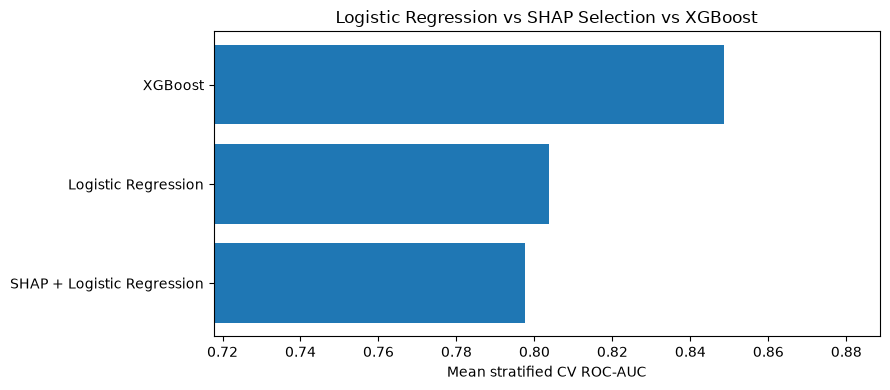


 Logistic Regression


,mean_test_score,std_test_score,params
6,0.803817,0.005359,"{'classifier__C': 0.1, 'classifier__class_weig..."
4,0.799689,0.005826,"{'classifier__C': 0.1, 'classifier__class_weig..."
8,0.788299,0.007230,"{'classifier__C': 1.0, 'classifier__class_weig..."
10,0.786629,0.006947,"{'classifier__C': 1.0, 'classifier__class_weig..."
7,0.779995,0.008654,"{'classifier__C': 0.1, 'classifier__class_weig..."



 SHAP + Logistic Regression


,mean_test_score,std_test_score,params
10,0.797697,0.015864,"{'classifier__C': 0.3, 'classifier__class_weig..."
16,0.796989,0.016593,"{'classifier__C': 3.0, 'classifier__class_weig..."
7,0.794989,0.017147,"{'classifier__C': 0.3, 'classifier__class_weig..."
13,0.794871,0.017529,"{'classifier__C': 3.0, 'classifier__class_weig..."
11,0.792360,0.014265,"{'classifier__C': 0.3, 'classifier__class_weig..."



 XGBoost


,mean_test_score,std_test_score,params
4,0.848636,0.010964,"{'classifier__learning_rate': 0.03, 'classifie..."
5,0.846000,0.009837,"{'classifier__learning_rate': 0.03, 'classifie..."
6,0.839421,0.007179,"{'classifier__learning_rate': 0.03, 'classifie..."
1,0.837289,0.008621,"{'classifier__learning_rate': 0.03, 'classifie..."
12,0.836397,0.010954,"{'classifier__learning_rate': 0.08, 'classifie..."


In [10]:
plt.figure(figsize=(9, 4))
plt.barh(results['Model'][::-1], results['CV ROC-AUC (mean)'][::-1])
plt.xlabel('Mean stratified CV ROC-AUC')
plt.title('Logistic Regression vs SHAP Selection vs XGBoost')
plt.xlim(max(0, results['CV ROC-AUC (mean)'].min()-0.08),
         min(1, results['CV ROC-AUC (mean)'].max()+0.04))
plt.tight_layout(); plt.show()
for name, search in searches.items():
    scores = pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(5)
    print('\n', name)
    display(scores[['mean_test_score', 'std_test_score', 'params']])

## 7 — Explain tuned models with SHAP

Plots come from **models refitted on all labeled training data** and serve for interpretation only; the CV selector was independently refit within each fold. SHAP model contributions for LR are in log-odds. For XGBoost we use `TreeExplainer`; samples are small to keep the notebook responsive.

,feature,mean_abs_SHAP
675,cat__subject_K,0.416259
236,num__y15,0.404500
509,num__z66,0.404407
7,num__x8,0.386772
507,num__z64,0.382379
672,cat__subject_G,0.381327
283,num__y62,0.342118
279,num__y58,0.330388
360,num__y139,0.291314
506,num__z63,0.279856


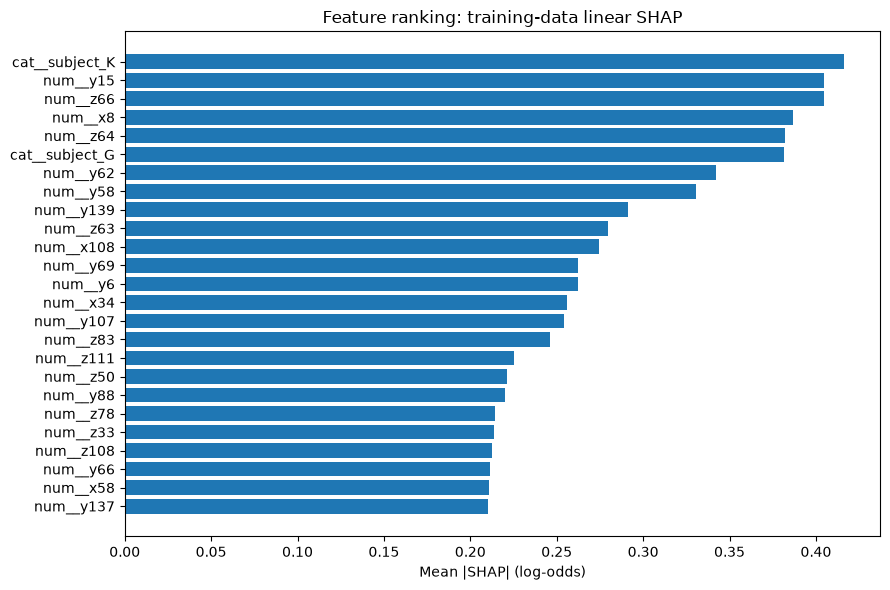

In [11]:
best_shap_lr = searches['SHAP + Logistic Regression'].best_estimator_
transformed = best_shap_lr.named_steps['preprocessor'].transform(X)
all_names = best_shap_lr.named_steps['preprocessor'].get_feature_names_out()
selector = best_shap_lr.named_steps['shap_select']
selected_names = all_names[selector.selected_indices_]
importance_table = pd.DataFrame({'feature': all_names, 'mean_abs_SHAP': selector.importances_})
importance_table = importance_table.sort_values('mean_abs_SHAP', ascending=False)
display(importance_table.head(25))
importance_table.to_csv(OUT_DIR / 'shap_feature_importance.csv', index=False)

plt.figure(figsize=(9, 6))
top25 = importance_table.head(25).iloc[::-1]
plt.barh(top25['feature'], top25['mean_abs_SHAP'])
plt.title('Feature ranking: training-data linear SHAP')
plt.xlabel('Mean |SHAP| (log-odds)')
plt.tight_layout(); plt.show()

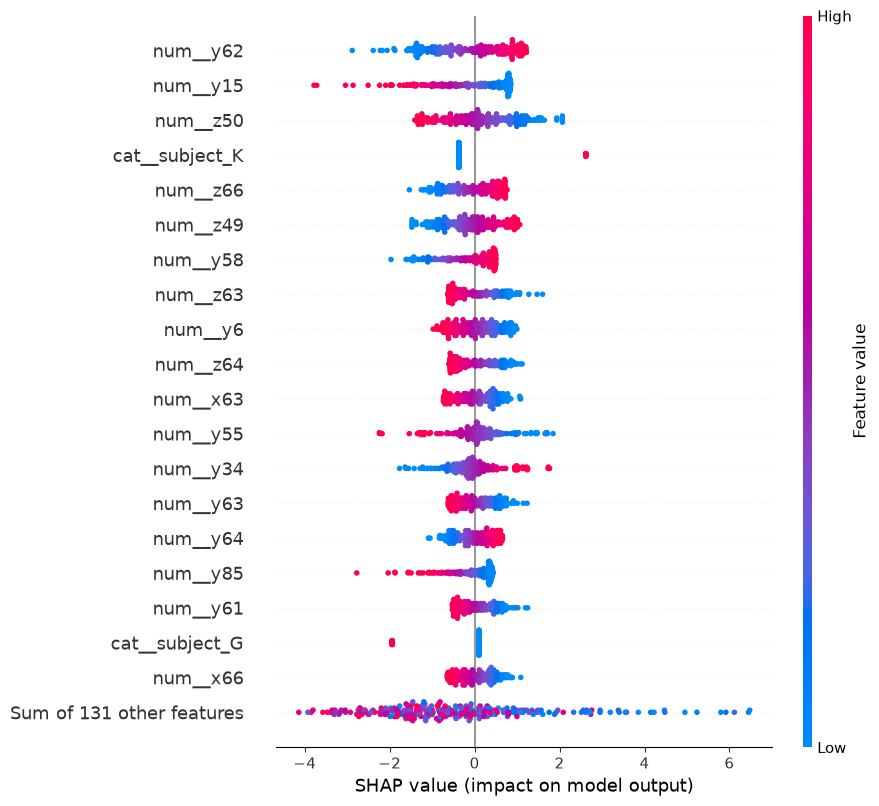

In [12]:
rng = np.random.default_rng(SEED)
ix = rng.choice(len(X), min(250, len(X)), replace=False)
selected_X = np.asarray(transformed)[ix][:, selector.selected_indices_]
bg_ix = rng.choice(len(X), min(80, len(X)), replace=False)
selected_bg = np.asarray(transformed)[bg_ix][:, selector.selected_indices_]
lr_explainer = shap.LinearExplainer(best_shap_lr.named_steps['classifier'], selected_bg)
lr_explanation = lr_explainer(selected_X)
lr_explanation.feature_names = list(selected_names)
shap.plots.beeswarm(lr_explanation, max_display=20, show=True)

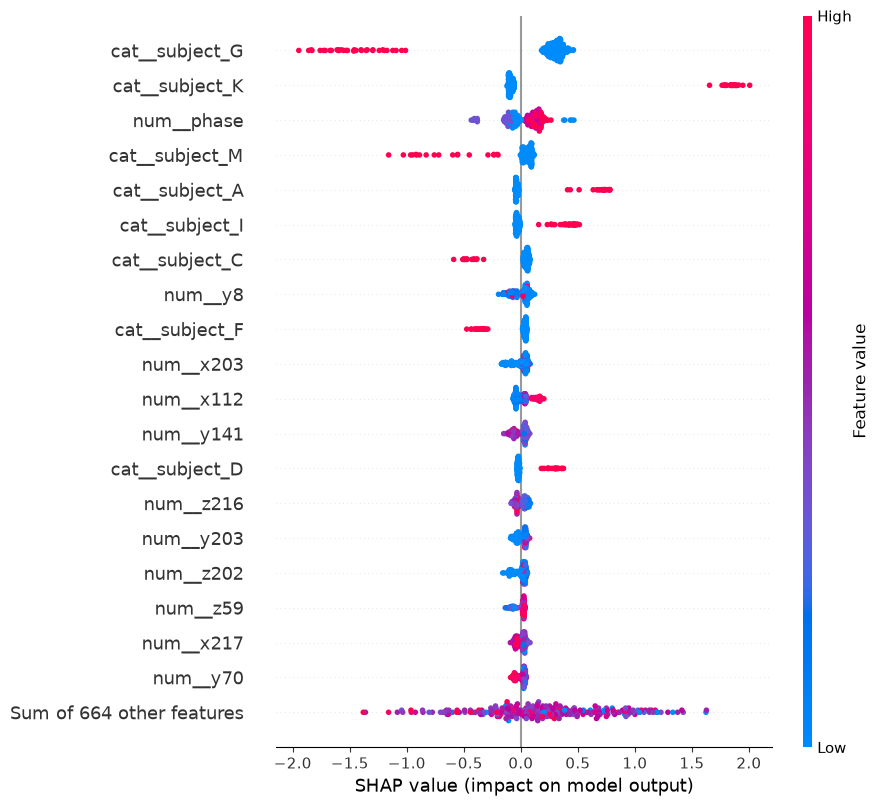

In [13]:
best_xgb = searches['XGBoost'].best_estimator_
transformed_xgb = np.asarray(best_xgb.named_steps['preprocessor'].transform(X))
xgb_names = list(best_xgb.named_steps['preprocessor'].get_feature_names_out())
xgb_explainer = shap.TreeExplainer(best_xgb.named_steps['classifier'])
xgb_explanation = xgb_explainer(transformed_xgb[ix])
xgb_explanation.feature_names = xgb_names
shap.plots.beeswarm(xgb_explanation, max_display=20, show=True)

## 8 — Select winning model and make Kaggle submission

The winner is determined by **mean stratified CV ROC-AUC**, not Kaggle's test leaderboard. Each `GridSearchCV(refit=True)` winner is already refitted on all training rows. The submission copies IDs and column order from `sample_solution.csv` (never invent IDs). Positive-class probabilities are written to `output`.

In [14]:
winner_name = results.iloc[0]['Model']
winner = searches[winner_name].best_estimator_
print('Winner:', winner_name)
print('CV ROC-AUC:', round(searches[winner_name].best_score_, 5))

# Models were automatically refitted on all labeled data by GridSearchCV.
test_probs = winner.predict_proba(X_test)[:, 1]
assert len(test_probs) == len(sample_solution)
assert np.isfinite(test_probs).all()
assert np.all((test_probs >= 0) & (test_probs <= 1))

submission = sample_solution.copy()
submission['output'] = test_probs
submission_path = OUT_DIR / 'shap_lr_vs_xgboost_submission.csv'
submission.to_csv(submission_path, index=False)
print('Saved:', submission_path.resolve())
print('Submission shape:', submission.shape)
display(submission.head())

dump(winner, OUT_DIR / 'winning_pipeline.joblib')

Winner: XGBoost
CV ROC-AUC: 0.84864
Saved: /Users/nilavaghosh/Desktop/E82Advanced ML/Homeworks/HW3/ml_classifier_experiments/src/shap_lr_vs_xgboost_submission.csv
Submission shape: (1732, 2)


,id,output
0,0,0.886187
1,1,0.924903
2,2,0.813863
3,3,0.801982
4,4,0.891557


['src/winning_pipeline.joblib']

## 9 — Optional: create one submission per model

Helpful for testing whether the public leaderboard agrees with cross-validation. Avoid repeatedly selecting a model solely on the public leaderboard; it can lead to overfitting.

In [ ]:
for name, search in searches.items():
    safe_name = name.lower().replace(' + ', '_').replace(' ', '_')
    entry = sample_solution.copy()
    entry['output'] = search.best_estimator_.predict_proba(X_test)[:, 1]
    path = OUT_DIR / f'{safe_name}_submission.csv'
    entry.to_csv(path, index=False)
    print(path)

## What to examine before submitting

- **Compare mean CV ROC-AUC and standard deviation**, not just best fold or training score.
- **Compare selected features:** the SHAP plot shows influence, not causality; correlated predictors can share importance.
- **Validate problem structure:** if `subject` identifies repeated observations and the goal is to generalize to *unseen subjects*, replace ordinary stratification with group-aware validation (such as `StratifiedGroupKFold`). Random stratification may overestimate performance in that setting.
- **Submission format:** check that the generated CSV has the same length, IDs, and columns as `sample_solution.csv`.
- **Performance:** for a faster first run set `N_SPLITS = 3`, shrink grids, and reduce SHAP explain/background samples. Switch to 5-fold before finalizing.

This notebook uses internal CV for model selection; the reported winning ROC-AUC is *not* an independent test-set estimate. For a publishable estimate, perform nested CV or reserve a holdout that is not used in tuning.